# Logistic regression

# Dataset:
German Credit

# Objective
Estimate default probabilities using logistic regression

# 1. Load Libraries and data

In [24]:
#importing all libraries for the Py notebook
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as pyplot
%matplotlib inline  

%config IPCompleter.greedy=True

# 2. Check how many records do we have


In [4]:
credit = pd.read_excel('German_Credit.xlsx')
credit.size

3000

In [5]:

credit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Creditability             1000 non-null   int64
 1   CreditAmount              1000 non-null   int64
 2   DurationOfCreditInMonths  1000 non-null   int64
dtypes: int64(3)
memory usage: 23.6 KB


In [6]:
credit.head()

,Creditability,CreditAmount,DurationOfCreditInMonths
0,1,1049,18
1,1,2799,9
2,1,841,12
3,1,2122,12
4,1,2171,12


In [7]:
credit.isnull().values.any()

False

The dataset has no null values in the dataset

# 3. Plot Histogram for column 'CreditAmount'

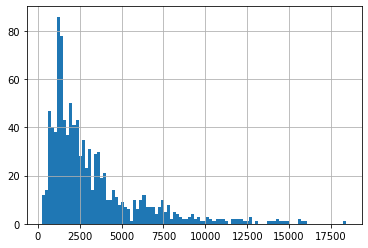

In [33]:
credit['CreditAmount'].hist(bins=100)
#sns.distplot(credit["CreditAmount"],kde=True)

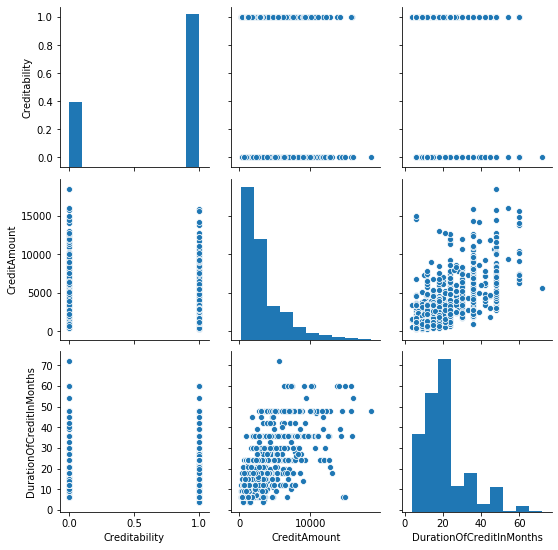

In [31]:
sns.pairplot(credit)

# 3b. Create creditability dataframe

In [8]:
credit.Creditability.value_counts()

1    700
0    300
Name: Creditability, dtype: int64

# 4. Concatenate the above 2 dataframes and give the total of Credibiliity0 and Credibiliity1

# 5. Plot Creditworthiness plot for Credibility == 0 and also ==1

# 6. Prepare input data for the model

In [9]:
credit.head()

y = credit.iloc[:,0]
X = credit.iloc[:,1:3]


from sklearn.model_selection import train_test_split

x_test, x_train, y_test , y_train = train_test_split(X,y,random_state=1, test_size=.3)

# 7. Fit logistic regression model

In [10]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear')
model.fit(x_train,y_train)

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=100,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=None, solver='liblinear', tol=0.0001, verbose=0,
                   warm_start=False)

In [11]:
print("Model coeff: {}".format(model.coef_))
print ("Model Intercept: {}".format(model.intercept_))


Model coeff: [[-2.86079244e-05 -2.36610393e-02]]
Model Intercept: [1.41494106]


In [12]:
model.score(x_train,y_train)

0.69

# 8. Test accuracy calculation

In [13]:
y_pred = model.predict(x_test)
test = pd.DataFrame()
test = test.append(x_test)
test['y'] = y_test
test['y_pred'] = y_pred

In [17]:
test.head()

,CreditAmount,DurationOfCreditInMonths,y,y_pred
731,6527,60,1,0
716,7476,48,1,1
640,2348,36,1,1
804,900,12,0,1
737,1149,18,1,1


# 9. Build a confusion matrix

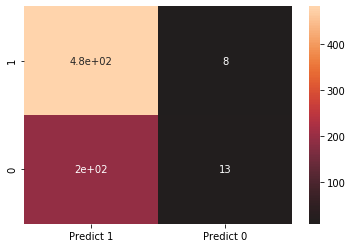

In [31]:
from sklearn import metrics

cm = metrics.confusion_matrix(y_test,y_pred , labels=[1,0])

cm_pd = pd.DataFrame(cm, index = [i for i in ["1","0"]],
                  columns = [i for i in ["Predict 1","Predict 0"]])

sns.heatmap(cm_pd,annot=True,center=0)

In [32]:
metrics.accuracy_score(y_test,y_pred)

0.7085714285714285

In [35]:
(cm[0,0]+ cm[1,1])/y_test.size

0.7085714285714285

# 10.  Predicted Probability distribution Plots for Defaults and Non Defaults

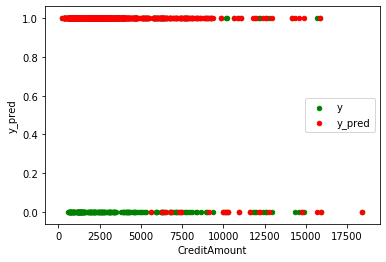

In [46]:
#sns.scatterplot(x="CreditAmount",y=["y","y_pred"], data = test, marker='X')

bx = test.plot(kind='scatter', x='CreditAmount',y='y',color = 'Green',label ='y')
bx = test.plot(kind='scatter', x='CreditAmount',y='y_pred',color = 'Red',label ='y_pred',ax=bx)